# Logistic regression

**Logistic regression** is a supervised learning algorithm used for **binary classification**, predicting whether an input belongs to one of two classes. It models the probability of an outcome using a sigmoid function, which maps inputs to a probability between 0 and 1. By adjusting weights through optimization, logistic regression finds the best decision boundary for separating classes.

## Outline
1. [Introduction](#1-introduction)
2. [The sigmoid function](#2-the-sigmoid-function)
3. [Binary cross entropy](#3-binary-cross-entropy)
4. [Data](#4-data)
5. [Gradient Computation for Logistic Regression with Binary Cross-Entropy Loss](#5-gradient-computation-for-logistic-regression-with-binary-cross-entropy-loss)
6. [Logistic regression implementation](#6-logistic-regression-implementation)
7. [Example usage](#7-example-usage)
8. [Testing with two features](#8-testing-with-two-features)
   - [A > B: Train and test from CSV data](#81-ab)
   - [A red corner](#82-a-red-corner)
9. [Polynomial logistic regression: Circle](#9-polynomial-logistic-regression-circle)
10. [Ideas to Deepen Your Knowledge](#10-ideas-to-deepen-your-knowledge)


## 1. Introduction
This Jupyter notebook implements logistic regression optimizing binary cross entropy loss using only the NumPy library (and MatPlotLib for display). It includes all the derivations of equations.

In [57]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

np.set_printoptions(precision=2)

## 2. The sigmoid function

The sigmoid function is a smooth, S-shaped function that maps any real-valued number to a value between 0 and 1. It can be interpreted as a smooth step function, which is particularly useful in binary classification tasks. The sigmoid function is defined as:
It is defined mathematically as:

$$
\sigma(z) = \frac{1}{1+e^{-z}}
\\
\sigma'(z) = \sigma(z)(1 - \sigma(z))
$$

In [58]:
def sigma(z):
    """The sigmoid function."""
    return 1 / (1 + np.e**(-1*z))

def d_sigma(z):
    """The derivative of the sigmoid function."""
    return sigma(z) * (1 - sigma(z))

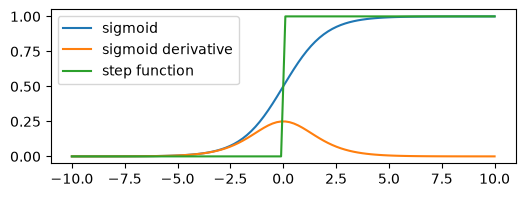

In [59]:
# Plot the sigmoid, its derivative and the step function
# ______________________________________________________
x = np.linspace(-10, 10, 100)
y1 = sigma(x)
y2 = d_sigma(x)

# set figure size
plt.figure(figsize=(6, 2))
plt.plot(x, y1, label='sigmoid')
plt.plot(x, y2, label='sigmoid derivative')
plt.plot(x, np.where(x >= 0, 1, 0), label='step function')
plt.legend()
plt.show()

## 3. Binary cross entropy

Cross-entropy measures how well one probability distribution predicts another. Its range is $[0, \infty)$, with 0 indicating perfect prediction. In binary classification, the binary cross-entropy (BCE) loss quantifies the difference between predicted probabilities and actual binary labels. 

Let $n$ be the number of examples and $m$ the number of features. For one example $i$, the BCE loss is:

$$
L^{(i)} = -\left( y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right)
$$

For $n$ examples, the average BCE loss is 

$$
\mathcal{L} = \frac{1}{n} \sum_{i=1}^{n} L^{(i)} = -\frac{1}{n} \sum_{i=1}^{n} \left( y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right)
$$

In vector notation, this can be expressed as:
$$
\mathcal{L} = -\frac{1}{n} \mathbf{1}^T \left( \mathbf{y} \odot \log(\hat{\mathbf{y}}) + (\mathbf{1} - \mathbf{y}) \odot \log(\mathbf{1} - \hat{\mathbf{y}}) \right)
$$



The derivative of the single-example loss with respect to its predicted output is:

$$
\frac{\partial L^{(i)}}{\partial \hat{y}^{(i)}} = -\left( \frac{y^{(i)}}{\hat{y}^{(i)}} - \frac{1 - y^{(i)}}{1 - \hat{y}^{(i)}} \right)
$$

And the derivative of the average loss with respect to the predicted outputs is:

$$
\frac{\partial \mathcal{L}}{\partial \hat{\mathbf{y}}} = -\frac{1}{n} \left( \frac{\mathbf{y}}{\hat{\mathbf{y}}} - \frac{1 - \mathbf{y}}{1 - \hat{\mathbf{y}}} \right)
$$

Note: In logistic regression, we need the per-example derivatives compute the parameter gradients.

In [60]:
# Binary cross entropy
# import numpy as np

def binary_cross_entropy(y, y_hat):
    """Compute mean binary cross entropy across n examples.
    
    Parameters:
    y (array-like): n binary labels (0 or 1), one-dimensional or column-shaped.
    y_hat (array-like): n predicted probabilities, one-dimensional or column-shaped.

    Returns:
    float: Mean binary cross entropy across n examples.
    """
    y = np.asarray(y).ravel()
    y_hat = np.asarray(y_hat).ravel()
    y_hat = np.clip(y_hat, 1e-15, 1 - 1e-15)     # to avoid log(0)
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))   #BCE loss averaged across n examples

def binary_cross_entropy_derivative(y, y_hat):
    """Compute each example's BCE derivatives with respect to y_hat (per example).
    
    Parameters:
    y (array-like): n binary labels (0 or 1), one-dimensional or column-shaped.
    y_hat (array-like): n predicted probabilities, one-dimensional or column-shaped.

    Returns:
    array-like: Per-example derivatives; We need the per-example derivatives to compute the parameter gradients.
    """
    y = np.asarray(y).ravel()
    y_hat = np.asarray(y_hat).ravel()
    return -((y - y_hat) / (y_hat * (1 - y_hat)))  # returns a vector of derivatives for each example


In [61]:
# These vectors contain n=8 examples.
y = [0, 0, 0, 0, 1, 1, 1, 1]
y_pred = [0.01, 0.0001, 0.2, 0.3, 0.9, 0.99, 0.9988, 0.99999]    # because of the sigmoid function, the values are in the interval (0, 1): never 0 or 1

print(binary_cross_entropy(y, y_pred))
binary_cross_entropy_derivative(y, y_pred)


0.08832380103057799


array([ 1.01,  1.  ,  1.25,  1.43, -1.11, -1.01, -1.  , -1.  ])

## 4. Data
We have artificial data with $n=100$ examples, one feature ($m=1$; the person's weight), and one binary target (whether they are obese). The feature matrix $X$ has shape $(n,m)=(100,1)$, and the labels are stored as a one-dimensional array with shape $(n,)=(100,)$. The model reshapes labels internally to $(n,1)$ for its matrix calculations.

**Scaling note:** This small example has no train/test split, so the scaler is fitted to all 100 feature values only to demonstrate scaling. For model evaluation, split the data first, fit the scaler on training features only, then use that same fitted scaler to transform both training and test features. Fitting on test data leaks information about the held-out set into the training process.

n=100 examples, m=1 feature(s); y has shape (100,)


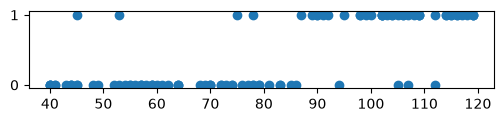

In [62]:
# Data

# weight in kgs
x = [40, 40, 40, 40, 41, 41, 43, 44, 44, 44, 45, 45, 45, 48, 49, 52, 53, 53, 54, 55, 55, 56, 57, 57, 57, 58, 59, 59, 59, 60, 61, 62, 64, 64, 64, 68, 69, 70, 70, 70, 72, 72, 73, 74, 74, 75, 76, 77, 78, 78, 78, 79, 79, 81, 83, 83, 85, 86, 87, 89, 90, 90, 91, 92, 94, 95, 98, 98, 99, 100, 102, 102, 102, 102, 103, 104, 104, 105, 105, 106, 106, 107, 107, 108, 109, 109, 109, 112, 112, 114, 114, 115, 115, 116, 116, 117, 118, 119, 119, 119]
# obese yes or no
y = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

# Arrange data as n rows (examples) and m columns (features)
x = np.array(x).reshape(-1, 1)
y = np.array(y)
n_examples, m_features = x.shape
print(f"n={n_examples} examples, m={m_features} feature(s); y has shape {y.shape}")

# scatter plot
plt.figure(figsize=(6, 1))
plt.scatter(x[:, 0], y)


In [63]:
class MinMaxScaler:
    def __init__(self):
        self.X_min = None
        self.X_max = None

    def fit(self, X):
        self.X_min = X.min(axis=0)     # one minimum per feature across n training examples
        self.X_max = X.max(axis=0)     # one maximum per feature across n training examples

    def transform(self, X):            # apply the scaling
        return 2 * (X - self.X_min) / (self.X_max - self.X_min) - 1
    
    def inverse_transform(self, X):    # reverse the scaling
        return (X + 1) * (self.X_max - self.X_min) / 2 + self.X_min
    


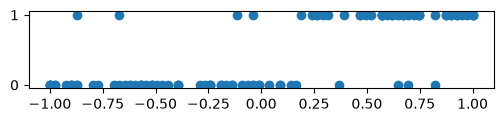

In [64]:
# Demonstration only: scale all data here because this example has no train/test split.
# For evaluation, fit on X_train only, then transform both X_train and X_test.

mm_scaler = MinMaxScaler()
mm_scaler.fit(x)                  # demonstration: learn parameters from all 100 examples
x = mm_scaler.transform(x)        # apply the scaling

# scatter plot
plt.figure(figsize=(6, 1))
plt.scatter(x, y)

## 5. Gradient Computation for Logistic Regression with Binary Cross-Entropy Loss

Step-by-step gradient computation for logistic regression; the derivation below works for any number of features.

### 5.1  Notation
- $ x^{(i)} = [x_1^{(i)}, \ldots, x_m^{(i)}]^T \in \mathbb{R}^m $ is the feature vector for example $ i $, where $ i=1,\ldots,n $.
- $ w = [w_1, \ldots, w_m]^T \in \mathbb{R}^m $ is the column vector of feature weights.
- $ b $ is the bias term.
- $ z^{(i)} $ is the weighted linear input for the $ i $-th example.
- $ \hat{y}^{(i)} $ is the predicted output for the $ i $-th example after applying the sigmoid function.
- $ y^{(i)} $ is the true label for the $ i $-th example (either 0 or 1).

The weighted input $ z^{(i)} $ and prediction $ \hat{y}^{(i)} $ are computed in the forward pass as:

$$
z^{(i)} = \sum_{j=1}^{m} x_j^{(i)} w_j + b
$$

$$
\hat{y}^{(i)} = \sigma(z^{(i)}) = \frac{1}{1 + e^{-z^{(i)}}}
$$

### 5.2 Binary Cross-Entropy Loss
The BCE loss for a single example $ i $ is:

$$
L^{(i)} = -\left( y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right)
$$

For all $ n $ examples, the average BCE loss is:

$$
\begin{aligned}
\mathcal{L} &= \frac{1}{n} \sum_{i=1}^{n} L^{(i)} \\
  &= -\frac{1}{n} \sum_{i=1}^{n} \left( y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right)
\end{aligned}
$$

### 5.3 Gradient of the Loss with Respect to the Predicted Output $\hat{y}$
The partial derivative of the loss $ L $ with respect to the predicted output $ \hat{y}^{(i)} $ for each example $ i $:

$$
\frac{\partial \mathcal{L}}{\partial \hat{y}^{(i)}} = -\frac{1}{n} \left( \frac{y^{(i)}}{\hat{y}^{(i)}} - \frac{1 - y^{(i)}}{1 - \hat{y}^{(i)}} \right)
$$

### 5.4 Gradient of the Predicted Output with Respect to $ z^{(i)} $
Since $ \hat{y}^{(i)} = \sigma(z^{(i)}) $, we use the derivative of the sigmoid function:

$$
\frac{d \sigma}{d z} = \sigma(z)(1 - \sigma(z))
$$
and get

$$
\frac{\partial \hat{y}^{(i)}}{\partial z^{(i)}} = \hat{y}^{(i)} \cdot (1 - \hat{y}^{(i)})
$$

Applying the chain rule to the average loss gives:

$$
\begin{aligned}
\frac{\partial \mathcal{L}}{\partial z^{(i)}} &= \frac{\partial \mathcal{L}}{\partial \hat{y}^{(i)}} \cdot \frac{\partial \hat{y}^{(i)}}{\partial z^{(i)}} \\[10pt]
&= -\frac{1}{n} \left( \frac{y^{(i)}}{\hat{y}^{(i)}} - \frac{1 - y^{(i)}}{1 - \hat{y}^{(i)}} \right) \cdot \hat{y}^{(i)} \cdot (1 - \hat{y}^{(i)}) \\[10pt]
&= \frac{1}{n} \left( \hat{y}^{(i)} - y^{(i)} \right)
\end{aligned}
$$

### 5.5 Gradients with Respect to Weights $ w $  and Bias $ b $
For each feature $ j=1,\ldots,m $, the weight gradient and the bias gradient are:

$$
\frac{\partial \mathcal{L}}{\partial w_j} = \frac{1}{n} \sum_{i=1}^{n} \left( \hat{y}^{(i)} - y^{(i)} \right) x_j^{(i)}, \qquad j=1,\ldots,m
$$

In matrix form, $ X \in \mathbb{R}^{n \times m} $ has one row per example and one column per feature, while $ w \in \mathbb{R}^{m \times 1} $ and $ y,\hat{y} \in \mathbb{R}^{n \times 1} $. The notebook stores target labels as one-dimensional arrays with shape $(n,)$; the custom model reshapes them to $(n,1)$ for these calculations:

$$
\nabla_w \mathcal{L} = \frac{1}{n} X^T (\hat{y} - y) \in \mathbb{R}^{m \times 1}
$$



$$
\frac{\partial \mathcal{L}}{\partial b} = \frac{1}{n} \sum_{i=1}^{n} \left( \hat{y}^{(i)} - y^{(i)} \right)
$$

### 5.6 Update the Parameters
Using these gradients, we update the parameters in the opposite direction of the gradient. For a learning rate $ \alpha $, the parameter updates are:

$$
w := w - \alpha \nabla_w \mathcal{L}
$$

$$
b := b - \alpha \frac{\partial \mathcal{L}}{\partial b}
$$


## 6. Logistic regression implementation
We need to define a class the methods:
- `__init__(self, [parameters])`, which initializes the classifier
- `fit(self, X, y)`, which fits the parameters of logistic regression to the data
- `predict_proba(self, X)`, which predicts probabilities
- `predict(self, X)`, which makes binary predictions
And auxiliary method
- `gradient_descent_step(self, X, y)`, which calculates the gradient for each weight w.r.t. the loss and updates the weights


In [65]:
class LogisticRegression:
    def __init__(self, epochs=1000, learning_rate=0.1, verbose=False) -> None:   
        """Initialize the weights"""      
        self.d_w = None     # derivatives of the loss w.r.t. the weights
        self.d_b = None     # derivative of the loss w.r.t. the bias
        self.epochs = epochs
        self.learning_rate = learning_rate
        self.verbose = verbose
        self.w = None       # we can not initialize yet because we do not know the number of features (m) until we see the training data. We will initialize it in the fit() method.
        self.b = None

    def predict_proba(self, X):
        """Return n predicted probabilities for an (n, m) feature matrix."""
        self.z = X @ self.w + self.b                # (n, m) @ (m, 1) + bias -> (n, 1)
        self.y_hat = sigma(self.z)                  # sigmoid activation
        return self.y_hat

    def predict(self, X, threshold=0.5):
        """Return one positive-class prediction per example, with shape (n,)."""
        return (self.predict_proba(X) >= threshold).ravel()

    def gradient_descent_step(self, X, y):
        """Update weights and bias from n labels, accepting shape (n,) or (n, 1)."""
        y = np.asarray(y).reshape(-1, 1)              # align labels with (n, 1) predictions
        n = y.shape[0]                                  # number of training examples
        self.d_w = (X.T @ (self.y_hat - y)) / n         # weight gradient; X has shape (n, m)
        self.d_b = np.sum(self.y_hat - y) / n           # bias gradient averaged over n examples
        
        # Gradient Descent Update: update weights opposite to the gradient, scaled by learning rate."""
        self.w -= self.learning_rate * self.d_w           # update the weights
        self.b -= self.learning_rate * self.d_b  

    def fit(self, X, y):
        """Train on X with n examples and m features and one-dimensional labels y."""
        y = np.asarray(y).reshape(-1, 1)           # column shape for matrix calculations
        # Initialize the weights
        m = X.shape[1]                            # number of features
        self.w = np.random.randn(m, 1) * 0.01     # m feature weights, stored as a column vector
        self.b = np.random.randn() * 0.01         # single bias (one number)
        # Train the model
        for i in range(self.epochs):
            y_hat = self.predict_proba(X)         # probabilities for all n training examples
            self.gradient_descent_step(X, y)      # compute the gradient and update the weights
            if self.verbose and i % 100 == 0:
                loss = binary_cross_entropy(y, y_hat)
                print(f'Epoch {i}, Loss: {loss:.3f}')

    def print_status(self):
        print("w, b =", self.w, self.b)


## 7. Example usage

In [66]:
# Example usage:
np.random.seed(42)  # For reproducibility

my_model = LogisticRegression(verbose=True)   # n=100 examples, m=1 feature, one output per example
my_model.print_status()

my_model.fit(x, y)
my_model.print_status()
y_hat = my_model.predict_proba(x)

w, b = None None
Epoch 0, Loss: 0.692
Epoch 100, Loss: 0.439
Epoch 200, Loss: 0.382
Epoch 300, Loss: 0.361
Epoch 400, Loss: 0.351
Epoch 500, Loss: 0.346
Epoch 600, Loss: 0.343
Epoch 700, Loss: 0.341
Epoch 800, Loss: 0.340
Epoch 900, Loss: 0.339
w, b = [[3.79]] -0.7167349523969705


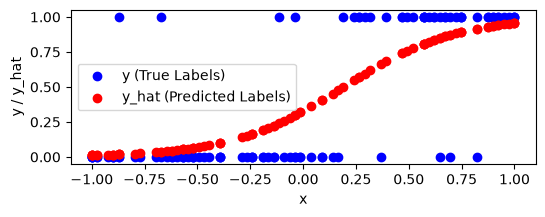

In [67]:

plt.figure(figsize=(6, 2))
plt.scatter(x[:, 0], y, color='blue', label='y (True Labels)')
plt.scatter(x[:, 0], y_hat.ravel(), color='red', label='y_hat (Predicted Labels)')
plt.xlabel('x')
plt.ylabel('y / y_hat')
plt.legend()
plt.show()

## 8. Testing with two features
### 8.1 A>B

Use the provided CSV files to train on $n_{\mathrm{train}}=300$ examples and evaluate on $n_{\mathrm{test}}=5000$ held-out examples. Each example has $m=3$ features ($A$, $B$, and $C$); the binary target is whether $A>B$.

We use the parameter $n_training$ to specify how many examples are used for training.


Training: X=(30, 3), y=(30,); test: X=(5000, 3), y=(5000,)


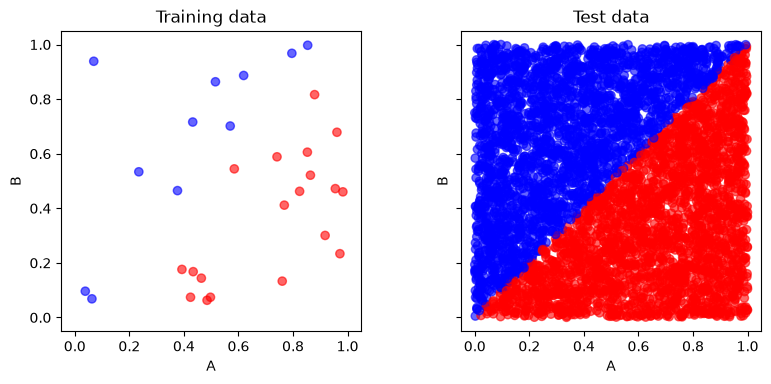

In [68]:
# Locate data/a_gt_b whether the notebook runs from its folder or the Hands-on root.
n_training = 30

data_dir = Path("../../data/a_gt_b")
train_df = pd.read_csv(data_dir /"trainABC.csv")
train_df = train_df.sample(n_training)
test_df = pd.read_csv(data_dir / "testABC.csv")

feature_columns = ["A", "B", "C"]
X_ab_train = train_df[feature_columns].to_numpy(dtype=float)
y_ab_train = train_df["A>B"].astype(int).to_numpy()
X_ab_test = test_df[feature_columns].to_numpy(dtype=float)
y_ab_test = test_df["A>B"].astype(int).to_numpy()
print(f"Training: X={X_ab_train.shape}, y={y_ab_train.shape}; test: X={X_ab_test.shape}, y={y_ab_test.shape}")

# Plot train and test examples, colored by whether A > B.
fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout="none", sharex=True, sharey=True)

axes[0].scatter(X_ab_train[:, 0], X_ab_train[:, 1], c=y_ab_train, cmap="bwr", vmin=0, vmax=1, alpha=0.6)
axes[0].set(xlabel="A", ylabel="B", title="Training data")
axes[0].set_box_aspect(1)

axes[1].scatter(X_ab_test[:, 0], X_ab_test[:, 1], c=y_ab_test, cmap="bwr", vmin=0, vmax=1, alpha=0.6)
axes[1].set(xlabel="A", ylabel="B", title="Test data")
axes[1].set_box_aspect(1)

# Fixed margins keep each square plotting area at 3 x 3 inches.
plt.subplots_adjust(left=0.1, right=0.975, bottom=0.18, top=0.93, wspace=1/3)
plt.show()

In [69]:
# Fit on the training CSV, then evaluate on the separate test CSV.
np.random.seed(42)
ab_model = LogisticRegression(epochs=5000, learning_rate=0.1)
ab_model.fit(X_ab_train, y_ab_train)
y_ab_train_pred = ab_model.predict(X_ab_train)
y_ab_test_pred = ab_model.predict(X_ab_test)
test_accuracy = np.mean(y_ab_test_pred == y_ab_test)
print(f"Test accuracy: {test_accuracy:.1%}")

Test accuracy: 95.9%


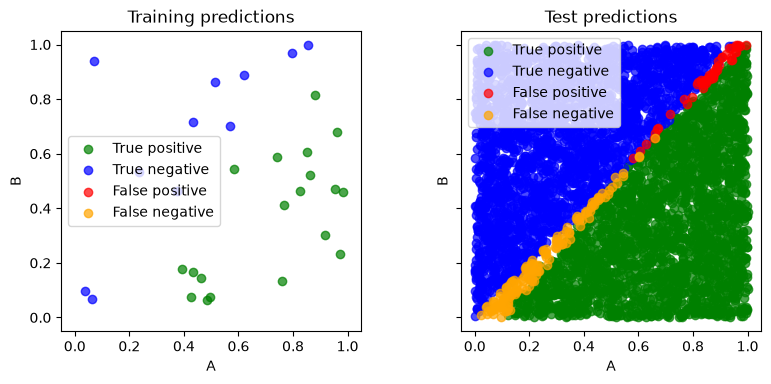

In [70]:
y_ab_train_pred = ab_model.predict(X_ab_train)
y_ab_test_pred = ab_model.predict(X_ab_test)

categories = [
    (1, 1, "True positive", "green"),
    (0, 0, "True negative", "blue"),
    (0, 1, "False positive", "red"),
    (1, 0, "False negative", "orange"),
]

fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout="none", sharex=True, sharey=True)

for true_label, pred_label, name, color in categories:
    train_mask = (y_ab_train == true_label) & (y_ab_train_pred == pred_label)
    test_mask = (y_ab_test == true_label) & (y_ab_test_pred == pred_label)

    axes[0].scatter(
        X_ab_train[train_mask, 0], X_ab_train[train_mask, 1],
        color=color, alpha=0.7, label=name,
    )
    axes[1].scatter(
        X_ab_test[test_mask, 0], X_ab_test[test_mask, 1],
        color=color, alpha=0.7, label=name,
    )


axes[0].set(xlabel="A", ylabel="B", title="Training predictions")
axes[0].set_box_aspect(1)
axes[0].legend()

axes[1].set(xlabel="A", ylabel="B", title="Test predictions")
axes[1].set_box_aspect(1)
axes[1].legend()

# Fixed margins keep each square plotting area at 3 x 3 inches.
plt.subplots_adjust(left=0.1, right=0.975, bottom=0.18, top=0.93, wspace=1/3)
plt.show()

### 8.2 A red corner
This synthetic example uses $n_{\mathrm{train}}=30$ training examples and $n_{\mathrm{test}}=1000$ test examples, each with $m=2$ features. Thus, $X_{\mathrm{train}}$ has shape $(30,2)$ and $X_{\mathrm{test}}$ has shape $(1000,2)$. Labels are one-dimensional arrays with shapes $(30,)$ and $(1000,)$; the custom model reshapes training labels internally for its matrix calculations.

In [ ]:
# Generate data
#_____________________________________________
# Generate data with n_train=30 and n_test=1000 examples, each with m=2 features.
# These data are not linearly separable, so it is not expected that the logistic regression will perform well on this dataset.
np.random.seed(42)
n_train = 30
n_test = 1000
m_features = 2
X_corner_train = np.random.randn(n_train, m_features)
X_corner_test = np.random.randn(n_test, m_features)
print(f"Training: n={n_train}, m={m_features}; test: n={n_test}, m={m_features}")
# Store one label per example in one-dimensional arrays; the negative-negative quadrant has label 1.
y_corner_train = ((X_corner_train[:, 0] < 0) & (X_corner_train[:, 1] < 0)).astype(int)
y_corner_test = ((X_corner_test[:, 0] < 0) & (X_corner_test[:, 1] < 0)).astype(int)

# scatter plot the two datasets side by side
plt.figure(figsize=(8, 4), layout="none")

plt.subplot(1, 2, 1)
plt.gca().set_box_aspect(1)
plt.scatter(X_corner_train[:, 0], X_corner_train[:, 1], c=y_corner_train, cmap='bwr')
plt.title('Training Data')
plt.xlabel('X1')
plt.ylabel('X2')

plt.subplot(1, 2, 2)
plt.gca().set_box_aspect(1)
plt.scatter(X_corner_test[:, 0], X_corner_test[:, 1], c=y_corner_test, cmap='bwr')
plt.title('Test Data')
plt.xlabel('X1')
plt.ylabel('X2')

# Fixed margins keep each square plotting area at 3 x 3 inches.
plt.subplots_adjust(left=0.1, right=0.975, bottom=0.18, top=0.93, wspace=1/3)
plt.show()


In [ ]:
# Initialize and fit the model
corner_model = LogisticRegression()
corner_model.fit(X_corner_train, y_corner_train)
# Make predictions
y_corner_pred = corner_model.predict(X_corner_test)


In [ ]:
# Plot the results and compare it with training data and ground truth
plt.figure(figsize=(8, 4), layout="none")

# Left plot: Predictions
plt.subplot(1, 2, 1)
plt.gca().set_box_aspect(1)
plt.scatter(X_corner_test[:, 0], X_corner_test[:, 1], c=y_corner_pred, cmap='bwr', alpha=0.5)
plt.scatter(X_corner_train[y_corner_train == 1][:, 0], X_corner_train[y_corner_train == 1][:, 1], color='green', edgecolor='black', label='Train Data y=1')
plt.title('Predictions')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()

# Right plot: Predictions highlighting false positives and false negatives
plt.subplot(1, 2, 2)
plt.gca().set_box_aspect(1)
plt.scatter(X_corner_test[:, 0], X_corner_test[:, 1], c=y_corner_test, cmap='bwr', alpha=0.5)
fp = (y_corner_test == 0) & (y_corner_pred == 1)
fn = (y_corner_test == 1) & (y_corner_pred == 0)
plt.scatter(X_corner_test[fp, 0], X_corner_test[fp, 1], color='yellow', edgecolor='black', label='False Positives')
plt.scatter(X_corner_test[fn, 0], X_corner_test[fn, 1], color='green', edgecolor='black', label='False Negatives')
plt.title('Predictions with False Positives/Negatives')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()

# Fixed margins keep each square plotting area at 3 x 3 inches.
plt.subplots_adjust(left=0.1, right=0.975, bottom=0.18, top=0.93, wspace=1/3)
plt.show()

## 9. Polynomial logistic regression: Circle
Let's generate $n_{\mathrm{train}}=100$ training examples and $n_{\mathrm{test}}=1000$ test examples with $m=2$ features. The one-dimensional target arrays have shapes $(n_{\mathrm{train}},)$ and $(n_{\mathrm{test}},)$. The data are not linearly separable, but become separable after adding polynomial features.

Training: n=100, m=2; test: n=1000, m=2


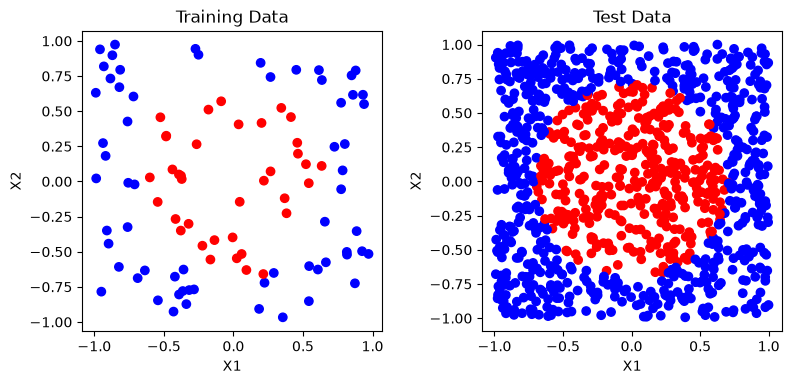

In [74]:
# Generate Data
#_____________________________________________________________
# Generate data with n_train=30 and n_test=1000 examples, each with m=2 features.
# These data are not linearly separable, so it is not expected that the logistic regression will perform well on this dataset.
np.random.seed(42)
n_train = 100
n_test = 1000
m_features = 2
X_train = np.random.uniform(-1, 1, size=(n_train, m_features))
X_test = np.random.uniform(-1, 1, size=(n_test, m_features))
print(f"Training: n={n_train}, m={m_features}; test: n={n_test}, m={m_features}")
y_train = ((X_train[:, 0]**2 + X_train[:, 1]**2) < 0.5).astype(int)
y_test = ((X_test[:, 0]**2 + X_test[:, 1]**2) < 0.5).astype(int)

# scatter plot the two datasets side by side
plt.figure(figsize=(8, 4), layout="none")

plt.subplot(1, 2, 1)
plt.gca().set_box_aspect(1)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='bwr')
plt.title('Training Data')
plt.xlabel('X1')
plt.ylabel('X2')

plt.subplot(1, 2, 2)
plt.gca().set_box_aspect(1)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='bwr')
plt.title('Test Data')
plt.xlabel('X1')
plt.ylabel('X2')

# Fixed margins keep each square plotting area at 3 x 3 inches.
plt.subplots_adjust(left=0.1, right=0.975, bottom=0.18, top=0.93, wspace=1/3)
plt.show()

In [ ]:
# Add quadratic terms: x1², x1*x2, and x2²
def polynomial_features(X):
    x1, x2 = X[:, 0], X[:, 1]
    return np.column_stack((x1, x2, x1**2, x1 * x2, x2**2))

X_train_poly = polynomial_features(X_train)
X_test_poly = polynomial_features(X_test)

np.random.seed(42)
poly_model = LogisticRegression()
poly_model.fit(X_train_poly, y_train)

y_poly_pred = poly_model.predict(X_test_poly)


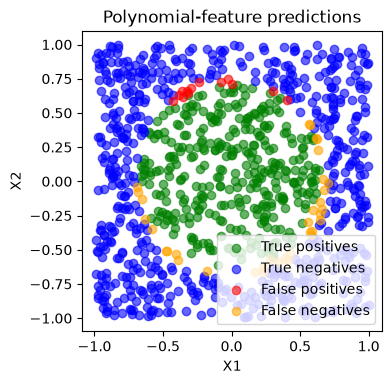

In [76]:
# Plot the decision boundary
#_____________________________________________

categories = [
    ((y_test == 1) & (y_poly_pred == 1), "True positives", "green"),
    ((y_test == 0) & (y_poly_pred == 0), "True negatives", "blue"),
    ((y_test == 0) & (y_poly_pred == 1), "False positives", "red"),
    ((y_test == 1) & (y_poly_pred == 0), "False negatives", "orange"),
]

plt.figure(figsize=(4, 4), layout="none")
plt.gca().set_box_aspect(1)
for mask, label, color in categories:
    plt.scatter(
        X_test[mask, 0],
        X_test[mask, 1],
        color=color,
        alpha=0.6,
        label=label,
    )

plt.title("Polynomial-feature predictions")
plt.xlabel("X1")
plt.ylabel("X2")
plt.legend(loc="lower right")
# Match the 3 x 3 inch plotting areas in the paired figures.
plt.subplots_adjust(left=0.2, right=0.95, bottom=0.18, top=0.93)
plt.show()

## 10. Ideas to Deepen Your Knowledge
- Compare the performance of our implementation of logistic regression to the one in SciKit-Learn.
- Use real datasets.
- Add the scaling/normalization of the input space in the fit function.
- Include L1 and/or L2 regularization.
- Implement the support for mini-batch stochastic gradient descent